In [1]:
!git clone https://github.com/shrutikushwaha2110-ux/Facial-Expression-Recognition-CNN

Cloning into 'Facial-Expression-Recognition-CNN'...
remote: Enumerating objects: 213, done.
remote: Counting objects: 100% (169/169), done.
remote: Compressing objects: 100% (157/157), done.
remote: Total 213 (delta 74), reused 3 (delta 2), pack-reused 44 (from 1)
Receiving objects: 100% (213/213), 128.90 MiB | 14.49 MiB/s, done.
Resolving deltas: 100% (75/75), done.


In [6]:
%cd /content/Facial-Expression-Recognition-CNN
!git status
!ls -la

/content/Facial-Expression-Recognition-CNN
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
total 40
drwxr-xr-x 7 root root 4096 Nov  5 02:03 .
drwxr-xr-x 1 root root 4096 Nov  5 02:03 ..
drwxr-xr-x 8 root root 4096 Nov  5 02:06 .git
-rw-r--r-- 1 root root   59 Nov  5 02:03 .gitignore
drwxr-xr-x 2 root root 4096 Nov  5 02:03 notebooks
drwxr-xr-x 4 root root 4096 Nov  5 02:03 Phase_3_Ablation_Experiments
drwxr-xr-x 4 root root 4096 Nov  5 02:03 Phase_4_Transfer_Learning
-rw-r--r-- 1 root root 5628 Nov  5 02:03 README.md
drwxr-xr-x 2 root root 4096 Nov  5 02:03 report


In [7]:
!find . -type f \( -name "*.keras" -o -name "*.h5" -o -name "*.pth" -o -name "*.pt" \)

./Phase_4_Transfer_Learning/models/fer2013_mobilenet_finetuned_best.keras
./Phase_3_Ablation_Experiments/models/phase3_batchnorm_off.keras
./Phase_3_Ablation_Experiments/models/phase3_optimizer_adam.keras
./Phase_3_Ablation_Experiments/models/phase3_with_augmentation.keras
./Phase_3_Ablation_Experiments/models/phase3_dropout_05.keras
./Phase_3_Ablation_Experiments/models/phase3_dropout_07.keras
./Phase_3_Ablation_Experiments/models/phase3_class_weights.keras
./Phase_3_Ablation_Experiments/models/phase3_four_block_cnn.keras
./Phase_3_Ablation_Experiments/models/phase3_batchnorm_on.keras
./Phase_3_Ablation_Experiments/models/phase3_oversampling.keras
./Phase_3_Ablation_Experiments/models/phase3_dropout_03.keras
./Phase_3_Ablation_Experiments/models/phase3_two_block_cnn.keras
./Phase_3_Ablation_Experiments/models/phase3_optimizer_sgd.keras
./Phase_3_Ablation_Experiments/models/phase3_without_augmentation.keras
./Phase_3_Ablation_Experiments/results/final_cnn_model.keras


In [8]:
!git switch -c exp/evaluation-explainability

Switched to a new branch 'exp/evaluation-explainability'


In [9]:
!git branch --show-current

exp/evaluation-explainability


In [10]:
!find . -type f \( -name "*.csv" -o -name "*.zip" \)

./Phase_3_Ablation_Experiments/results/phase3_depth_results.csv


In [12]:
!cat Phase_4_Transfer_Learning/README.md

# Phase 4: Transfer Learning (MobileNetV2)

This phase explores transfer learning using **MobileNetV2** pre-trained on ImageNet, adapted for facial expression recognition on the FER-2013 dataset.

## ⚙️ Process & Methodology Followed

1. **Data Preprocessing & Resizing (`prepare_mb_data`)**
   * Scaled and resized native $48 \times 48$ grayscale arrays to $96 \times 96$ pixels.
   * Converted single-channel inputs into 3-channel RGB tensors to match MobileNetV2 architecture requirements.
   * Normalized pixel ranges from $[0, 1]$ to $[-1, 1]$.

2. **Class Weight Optimization**
   * Calculated automated class weights using `scikit-learn` to combat category imbalances across emotion classes (Angry, Disgust, Fear, Happy, Sad, Surprise, Neutral).

3. **Stage 1: Feature Extraction**
   * Loaded **MobileNetV2** pre-trained on ImageNet with weights frozen (`base_model.trainable = False`).
   * Attached a custom classification head (`GlobalAveragePooling2D`, `Dense(256)`, `Dropout(0.5)`, and `

In [13]:
!find Phase_4_Transfer_Learning -type f | sort

Phase_4_Transfer_Learning/models/fer2013_mobilenet_finetuned_best.keras
Phase_4_Transfer_Learning/models/README.md
Phase_4_Transfer_Learning/README.md
Phase_4_Transfer_Learning/results/Confusion_Matrix_Feature_Extraction.jpeg
Phase_4_Transfer_Learning/results/Confusion_Matrix_Fine-Tuning.jpeg
Phase_4_Transfer_Learning/results/Feature Extraction Classification Report.txt
Phase_4_Transfer_Learning/results/Fine-Tuning_Classification Report.txt


In [14]:
import os

for file in os.listdir("/content"):
    print(file)

.config
fer2013_preprocessed.npz.zip
Facial-Expression-Recognition-CNN
final_cnn_model.keras.zip
fer2013_mobilenet_finetuned_best.keras.zip
sample_data


In [17]:
import zipfile

file_path = "/content/fer2013_preprocessed.npz.zip"

with zipfile.ZipFile(file_path, "r") as z:
    print("Files inside the ZIP:")
    print(z.namelist())
    print("\nZIP integrity:", z.testzip())

Files inside the ZIP:
['X_train.npy', 'y_train.npy', 'X_val.npy', 'y_val.npy', 'X_test.npy', 'y_test.npy']

ZIP integrity: None


In [18]:
import zipfile

zip_path = "/content/fer2013_preprocessed.npz.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/fer_dataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [19]:
import numpy as np

X_test = np.load("/content/fer_dataset/X_test.npy")
y_test = np.load("/content/fer_dataset/y_test.npy")

print("Test images shape:", X_test.shape)
print("Test labels shape:", y_test.shape)
print("Image data type:", X_test.dtype)
print("Label data type:", y_test.dtype)
print("Pixel range:", X_test.min(), "to", X_test.max())

Test images shape: (7178, 48, 48, 1)
Test labels shape: (7178,)
Image data type: float32
Label data type: int64
Pixel range: 0.0 to 1.0


Step 1: Load the Custom CNN
In this step, we load the already-trained Custom CNN model from the project directory. We will use this saved model to evaluate its performance on the preprocessed test dataset. No training is performed.

In [21]:
from tensorflow.keras.models import load_model

custom_cnn_path = (
    "/content/Facial-Expression-Recognition-CNN/"
    "Phase_3_Ablation_Experiments/results/final_cnn_model.keras"
)

custom_cnn = load_model(custom_cnn_path)

print("Custom CNN loaded!")
print("Input shape:", custom_cnn.input_shape)
print("Output shape:", custom_cnn.output_shape)

Custom CNN loaded!
Input shape: (None, 48, 48, 1)
Output shape: (None, 7)


Step 2: Generate Predictions
We pass the preprocessed test images through the saved Custom CNN to obtain predicted class scores. We select the class with the highest score as the predicted emotion and compare it with the true label.

In [22]:
import numpy as np

# Generate class scores for all test images
custom_cnn_probs = custom_cnn.predict(X_test, verbose=1)

# Convert scores into predicted class labels
custom_cnn_preds = np.argmax(custom_cnn_probs, axis=1)

print("Predictions shape:", custom_cnn_preds.shape)
print("First 10 predictions:", custom_cnn_preds[:10])
print("First 10 true labels:", y_test[:10])

225/225 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step
Predictions shape: (7178,)
First 10 predictions: [0 0 4 0 0 2 0 0 6 0]
First 10 true labels: [0 0 0 0 0 0 0 0 0 0]


Step 3: Calculate Evaluation Metrics
We compare the predicted labels with the true labels to calculate the model’s test accuracy, precision, recall, and F1-score. These metrics summarize its performance across the seven emotion classes.

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

custom_cnn_accuracy = accuracy_score(y_test, custom_cnn_preds)
custom_cnn_precision = precision_score(
    y_test, custom_cnn_preds, average="macro", zero_division=0
)
custom_cnn_recall = recall_score(
    y_test, custom_cnn_preds, average="macro", zero_division=0
)
custom_cnn_f1 = f1_score(
    y_test, custom_cnn_preds, average="macro", zero_division=0
)

print(f"Test Accuracy: {custom_cnn_accuracy:.4f}")
print(f"Macro Precision: {custom_cnn_precision:.4f}")
print(f"Macro Recall: {custom_cnn_recall:.4f}")
print(f"Macro F1-score: {custom_cnn_f1:.4f}")

Test Accuracy: 0.5653
Macro Precision: 0.5367
Macro Recall: 0.5575
Macro F1-score: 0.5443


Step 4: Classification Report
We generate a classification report to examine the model’s precision, recall, and F1-score for each emotion class. This helps identify which emotions the model recognizes well and which ones it struggles to classify.

In [24]:
from sklearn.metrics import classification_report

class_names = [
    "Angry", "Disgust", "Fear", "Happy",
    "Sad", "Surprise", "Neutral"
]

print(classification_report(
    y_test,
    custom_cnn_preds,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

       Angry       0.45      0.50      0.48       958
     Disgust       0.49      0.59      0.54       111
        Fear       0.38      0.34      0.36      1024
       Happy       0.82      0.77      0.80      1774
         Sad       0.46      0.37      0.41      1247
    Surprise       0.66      0.75      0.70       831
     Neutral       0.49      0.58      0.53      1233

    accuracy                           0.57      7178
   macro avg       0.54      0.56      0.54      7178
weighted avg       0.57      0.57      0.56      7178



Step 5: Confusion Matrix
We create a confusion matrix to compare the true emotion labels with the model’s predicted labels. The diagonal shows correct predictions, while off-diagonal values show which emotions are being misclassified.

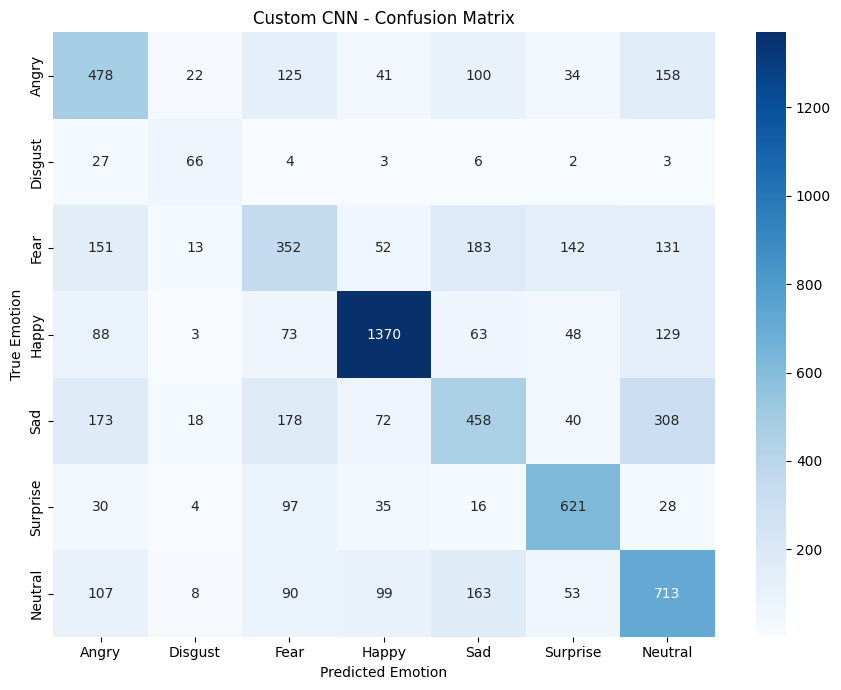

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, custom_cnn_preds)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Custom CNN - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.show()

Step 6: Normalized Confusion Matrix
We normalize each row of the confusion matrix so that the values represent proportions of the true emotion class. This helps compare classification performance across emotion classes despite differences in their sample counts.

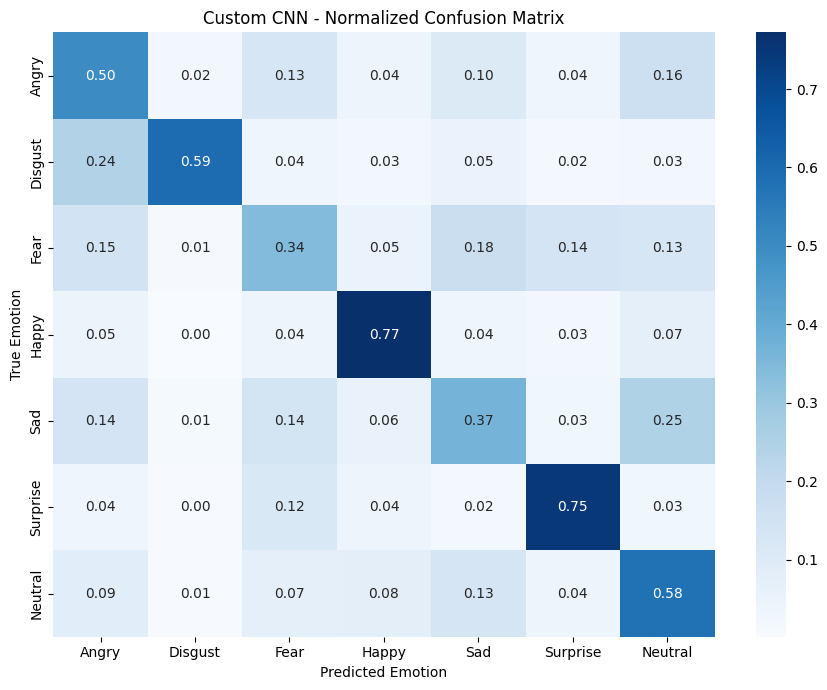

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_normalized = confusion_matrix(
    y_test,
    custom_cnn_preds,
    normalize="true"
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Custom CNN - Normalized Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.show()

Step 7: Inspect Misclassified Images
We identify test images where the predicted emotion differs from the true emotion. Displaying a sample of these images helps us visually inspect common classification errors.

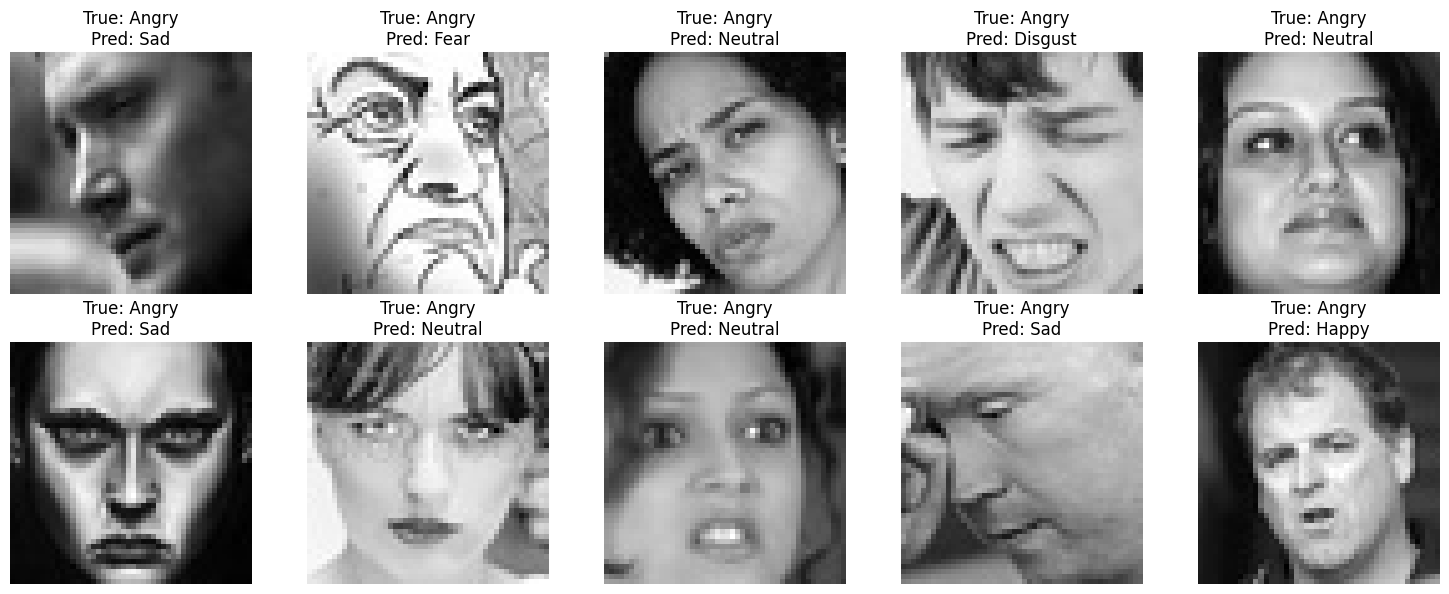

Total misclassified images: 3120


In [27]:
import matplotlib.pyplot as plt
import numpy as np

# Find indices where the prediction is incorrect
misclassified_indices = np.where(custom_cnn_preds != y_test)[0]

# Display up to 10 misclassified images
num_images = min(10, len(misclassified_indices))

plt.figure(figsize=(15, 6))

for i, idx in enumerate(misclassified_indices[:num_images]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    actual_emotion = class_names[y_test[idx]]
    predicted_emotion = class_names[custom_cnn_preds[idx]]

    plt.title(f"True: {actual_emotion}\nPred: {predicted_emotion}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Total misclassified images:", len(misclassified_indices))

Step 8: Save Evaluation Results
We save the Custom CNN’s evaluation metrics and classification report to the project’s results directory so they can be compared with the other models later.

In [28]:
import os
import json
from sklearn.metrics import classification_report

results_dir = (
    "/content/Facial-Expression-Recognition-CNN/"
    "results/evaluation_explainability"
)
os.makedirs(results_dir, exist_ok=True)

custom_cnn_results = {
    "model": "Custom CNN",
    "test_samples": int(len(y_test)),
    "misclassified_samples": int(len(misclassified_indices)),
    "accuracy": float(custom_cnn_accuracy),
    "macro_precision": float(custom_cnn_precision),
    "macro_recall": float(custom_cnn_recall),
    "macro_f1": float(custom_cnn_f1),
    "classification_report": classification_report(
        y_test,
        custom_cnn_preds,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
}

with open(
    os.path.join(results_dir, "custom_cnn_metrics.json"),
    "w"
) as f:
    json.dump(custom_cnn_results, f, indent=4)

print("Saved metrics to:", results_dir)

Saved metrics to: /content/Facial-Expression-Recognition-CNN/results/evaluation_explainability


Step 9: Save Confusion Matrices
We save the raw and normalized confusion matrices as PNG images in the evaluation results folder for documentation and comparison.

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Ensure the output folder exists
os.makedirs(results_dir, exist_ok=True)

# Raw confusion matrix
cm = confusion_matrix(y_test, custom_cnn_preds)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Custom CNN - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.savefig(
    os.path.join(results_dir, "custom_cnn_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Normalized confusion matrix
cm_normalized = confusion_matrix(
    y_test,
    custom_cnn_preds,
    normalize="true"
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Custom CNN - Normalized Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.savefig(
    os.path.join(results_dir, "custom_cnn_normalized_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Confusion matrix plots saved.")

Step 9: Save Confusion Matrices
We save the raw and normalized confusion matrices as PNG images in the evaluation results folder for documentation and comparison.

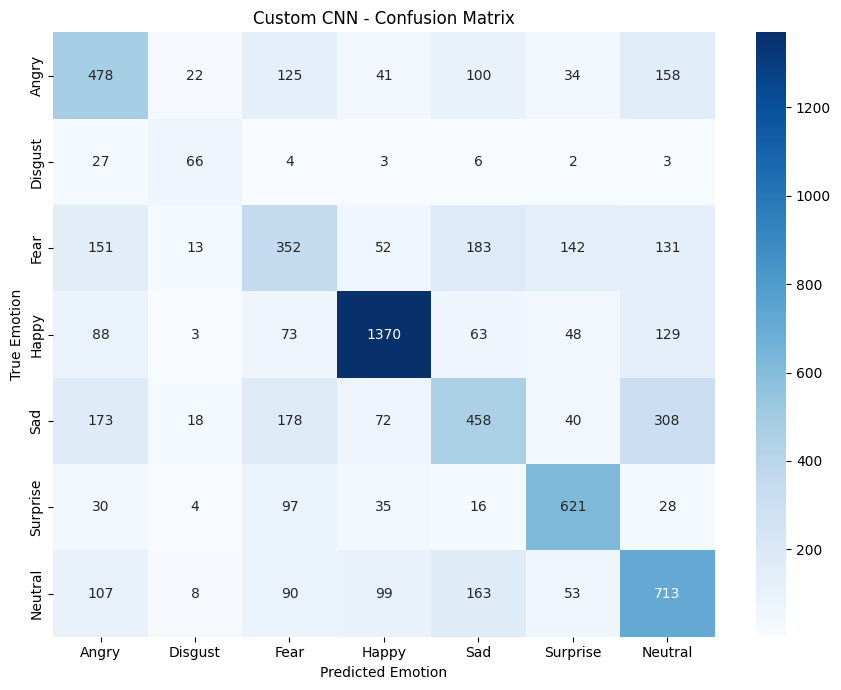

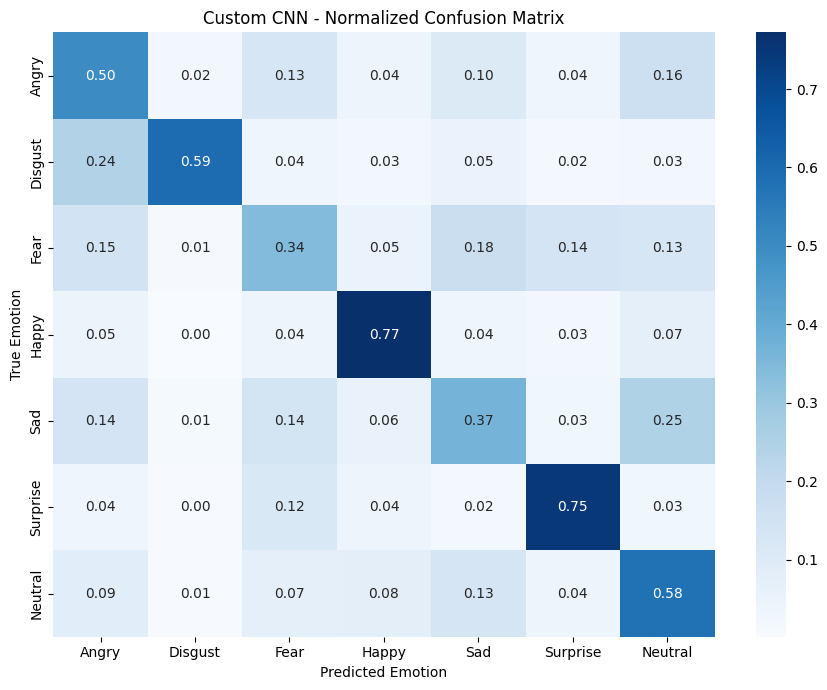

Confusion matrix plots saved.


In [29]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Ensure the output folder exists
os.makedirs(results_dir, exist_ok=True)

# Raw confusion matrix
cm = confusion_matrix(y_test, custom_cnn_preds)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Custom CNN - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.savefig(
    os.path.join(results_dir, "custom_cnn_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Normalized confusion matrix
cm_normalized = confusion_matrix(
    y_test,
    custom_cnn_preds,
    normalize="true"
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Custom CNN - Normalized Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.savefig(
    os.path.join(results_dir, "custom_cnn_normalized_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Confusion matrix plots saved.")

Step 10: Save Misclassified Image Samples
We save a grid of misclassified test images with their true and predicted emotion labels. This visual sample helps us inspect the model’s errors during analysis.

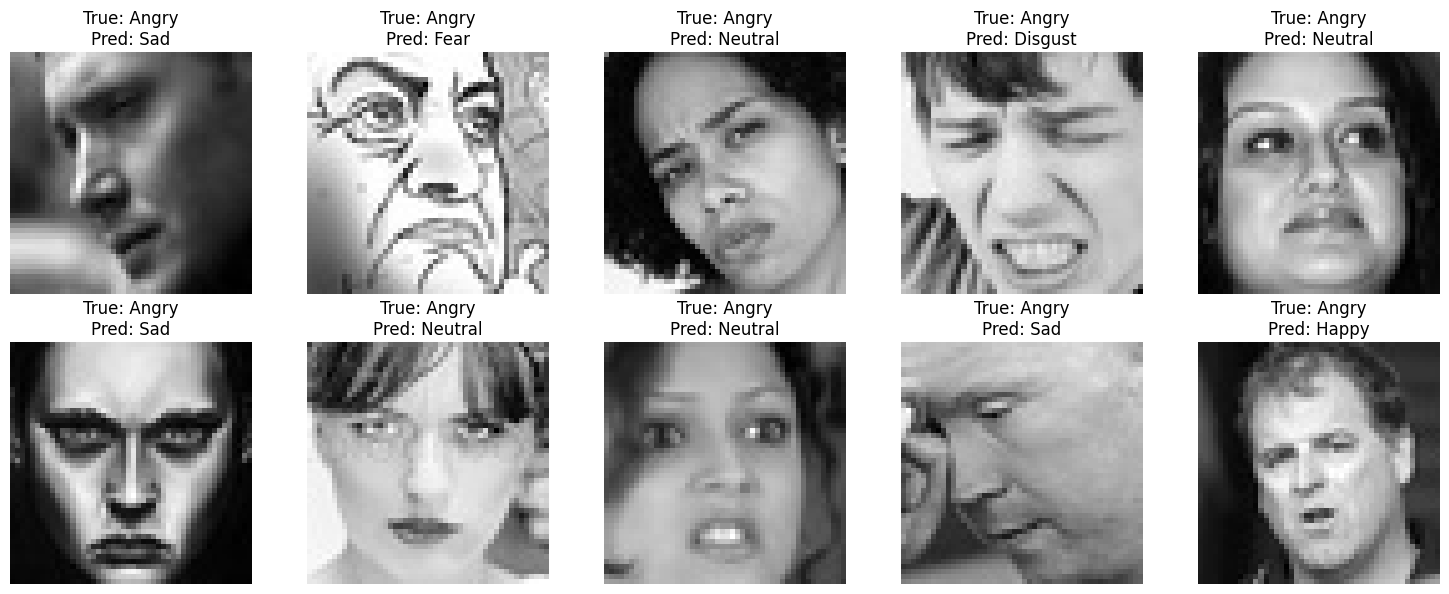

Misclassified-image plot saved.


In [30]:
import os
import matplotlib.pyplot as plt
import numpy as np

num_images = min(10, len(misclassified_indices))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i in range(num_images):
    idx = misclassified_indices[i]
    axes[i].imshow(X_test[idx].squeeze(), cmap="gray")
    axes[i].set_title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[custom_cnn_preds[idx]]}"
    )
    axes[i].axis("off")

# Hide unused axes if fewer than 10 errors are available
for i in range(num_images, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.savefig(
    os.path.join(results_dir, "custom_cnn_misclassified_samples.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Misclassified-image plot saved.")

Step 11: Identify the Grad-CAM Layer
Grad-CAM uses feature maps and gradients from a convolutional layer to highlight image regions that influenced a prediction. We inspect the model’s layers to identify a suitable convolutional layer.

In [31]:
for i, layer in enumerate(custom_cnn.layers):
    print(i, layer.name, layer.output.shape)

0 sequential_11 (None, 48, 48, 1)
1 conv2d_45 (None, 48, 48, 32)
2 batch_normalization_42 (None, 48, 48, 32)
3 max_pooling2d_45 (None, 24, 24, 32)
4 conv2d_46 (None, 24, 24, 64)
5 batch_normalization_43 (None, 24, 24, 64)
6 max_pooling2d_46 (None, 12, 12, 64)
7 conv2d_47 (None, 12, 12, 128)
8 batch_normalization_44 (None, 12, 12, 128)
9 max_pooling2d_47 (None, 6, 6, 128)
10 flatten_15 (None, 4608)
11 dense_30 (None, 128)
12 dropout_15 (None, 128)
13 dense_31 (None, 7)


Step 12: Create the Grad-CAM Model
We create a model that returns the feature maps from the final convolutional layer and the Custom CNN’s predictions. These outputs are used to generate Grad-CAM heatmaps showing which image regions influenced the predicted emotion.

In [37]:
import tensorflow as tf

# Build an explicit graph from the saved model's layers
grad_input = tf.keras.Input(shape=(48, 48, 1))
x = grad_input
conv_output = None

for layer in custom_cnn.layers:
    x = layer(x)
    if layer.name == "conv2d_47":
        conv_output = x

grad_model = tf.keras.Model(
    inputs=grad_input,
    outputs=[conv_output, x]
)

print("Grad-CAM model created.")

Grad-CAM model created.


Step 13: Visualize Grad-CAM Heatmap
We select a correctly classified test image and generate its Grad-CAM heatmap. We overlay the heatmap on the original grayscale image to visualize which facial regions influenced the model’s predicted emotion.

In [39]:
def make_gradcam_heatmap(image, model):
    image_tensor = tf.convert_to_tensor(
        image[np.newaxis, ...],
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = model(image_tensor, training=False)
        predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    gradients = tape.gradient(class_score, conv_outputs)
    weights = tf.reduce_mean(gradients, axis=(1, 2))

    conv_outputs = conv_outputs[0]
    weights = weights[0]

    heatmap = tf.reduce_sum(conv_outputs * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), int(predicted_class.numpy())

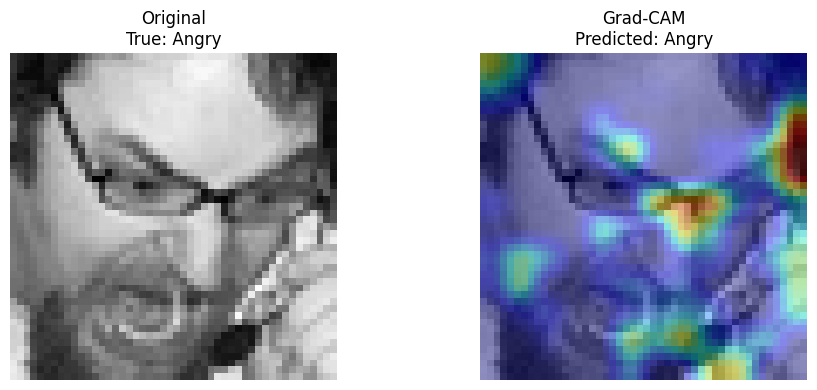

In [40]:
# Select a correctly classified test image
correct_indices = np.where(custom_cnn_preds == y_test)[0]
sample_idx = int(correct_indices[0])

# Generate Grad-CAM heatmap
heatmap, predicted_class = make_gradcam_heatmap(
    X_test[sample_idx],
    grad_model
)

# Resize heatmap to match the original image
heatmap_resized = cv2.resize(heatmap, (48, 48))

# Display original image and Grad-CAM overlay
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_test[sample_idx].squeeze(), cmap="gray")
plt.title(f"Original\nTrue: {class_names[y_test[sample_idx]]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(X_test[sample_idx].squeeze(), cmap="gray")
plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
plt.title(f"Grad-CAM\nPredicted: {class_names[predicted_class]}")
plt.axis("off")

plt.tight_layout()
plt.show()

Step 14: Save Grad-CAM Visualization
We save the Grad-CAM overlay as an image file for documentation and later comparison with the other models.

In [41]:
plt.savefig(
    os.path.join(results_dir, "custom_cnn_gradcam.png"),
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

Evaluation of MobileNetV2 Fine-Tuned Model
In this section, we evaluate the saved fine-tuned MobileNetV2 model using the same FER-2013 test set used for the Custom CNN. We will measure its performance and generate visualizations without retraining the model.

Step 1: Load the Fine-Tuned MobileNetV2 Model (Text cell):
We load the previously trained and saved MobileNetV2 fine-tuned model and inspect its input and output shapes before evaluation

In [42]:
from tensorflow.keras.models import load_model

mobilenet_ft_path = (
    "/content/Facial-Expression-Recognition-CNN/"
    "Phase_4_Transfer_Learning/models/"
    "fer2013_mobilenet_finetuned_best.keras"
)

mobilenet_ft = load_model(mobilenet_ft_path)

print("Fine-tuned MobileNetV2 loaded!")
print("Input shape:", mobilenet_ft.input_shape)
print("Output shape:", mobilenet_ft.output_shape)

Fine-tuned MobileNetV2 loaded!
Input shape: (None, 96, 96, 3)
Output shape: (None, 7)


Step 2: Prepare Test Images for MobileNetV2
We prepare the test images to match the input format expected by the saved MobileNetV2 model. The images are resized from 48×48 to 96×96, converted from grayscale to RGB, and scaled from [0, 1] to [-1, 1]. This prepares the test data for evaluation without retraining or modifying the model.

In [43]:
import tensorflow as tf
import numpy as np

# Resize test images from 48x48 to 96x96
X_test_resized = tf.image.resize(X_test, (96, 96))

# Convert grayscale images to 3-channel RGB
X_test_rgb = tf.image.grayscale_to_rgb(X_test_resized)

# Scale pixel values from [0, 1] to [-1, 1]
X_test_mobilenet = (X_test_rgb * 2.0) - 1.0

print("Test images shape:", X_test_mobilenet.shape)
print("Pixel range:",
      float(tf.reduce_min(X_test_mobilenet)),
      "to",
      float(tf.reduce_max(X_test_mobilenet)))

Test images shape: (7178, 96, 96, 3)
Pixel range: -1.0 to 1.0


We pass the preprocessed test images through the saved fine-tuned MobileNetV2 model to obtain predicted emotion scores. We select the class with the highest score for each image.

In [44]:
mobilenet_ft_probs = mobilenet_ft.predict(
    X_test_mobilenet,
    batch_size=32,
    verbose=1
)

mobilenet_ft_preds = np.argmax(mobilenet_ft_probs, axis=1)

print("Predictions shape:", mobilenet_ft_preds.shape)
print("First 10 predictions:", mobilenet_ft_preds[:10])
print("First 10 true labels:", y_test[:10])

225/225 ━━━━━━━━━━━━━━━━━━━━ 483s 2s/step
Predictions shape: (7178,)
First 10 predictions: [0 0 4 3 2 2 2 0 6 0]
First 10 true labels: [0 0 0 0 0 0 0 0 0 0]


We compare the predicted labels with the true test labels to calculate accuracy, macro precision, macro recall, and macro F1-score. These metrics summarize the fine-tuned MobileNetV2 model’s performance across the seven emotion classes.

In [45]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

mobilenet_ft_accuracy = accuracy_score(y_test, mobilenet_ft_preds)
mobilenet_ft_precision = precision_score(
    y_test, mobilenet_ft_preds, average="macro", zero_division=0
)
mobilenet_ft_recall = recall_score(
    y_test, mobilenet_ft_preds, average="macro", zero_division=0
)
mobilenet_ft_f1 = f1_score(
    y_test, mobilenet_ft_preds, average="macro", zero_division=0
)

print(f"Test Accuracy: {mobilenet_ft_accuracy:.4f}")
print(f"Macro Precision: {mobilenet_ft_precision:.4f}")
print(f"Macro Recall: {mobilenet_ft_recall:.4f}")
print(f"Macro F1-score: {mobilenet_ft_f1:.4f}")

Test Accuracy: 0.5687
Macro Precision: 0.5451
Macro Recall: 0.5641
Macro F1-score: 0.5525


We generate a classification report to examine precision, recall, and F1-score for each emotion class. This helps identify which emotions the fine-tuned MobileNetV2 recognizes well and which ones it struggles to classify.

In [46]:
from sklearn.metrics import classification_report

class_names = [
    "Angry", "Disgust", "Fear", "Happy",
    "Sad", "Surprise", "Neutral"
]

print(classification_report(
    y_test,
    mobilenet_ft_preds,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

       Angry       0.45      0.50      0.47       958
     Disgust       0.48      0.62      0.54       111
        Fear       0.44      0.38      0.41      1024
       Happy       0.77      0.75      0.76      1774
         Sad       0.46      0.43      0.44      1247
    Surprise       0.71      0.71      0.71       831
     Neutral       0.51      0.56      0.53      1233

    accuracy                           0.57      7178
   macro avg       0.55      0.56      0.55      7178
weighted avg       0.57      0.57      0.57      7178



We create a confusion matrix to compare the true emotion labels with the model’s predicted labels. The diagonal shows correct predictions, while off-diagonal values show which emotions are being misclassified.

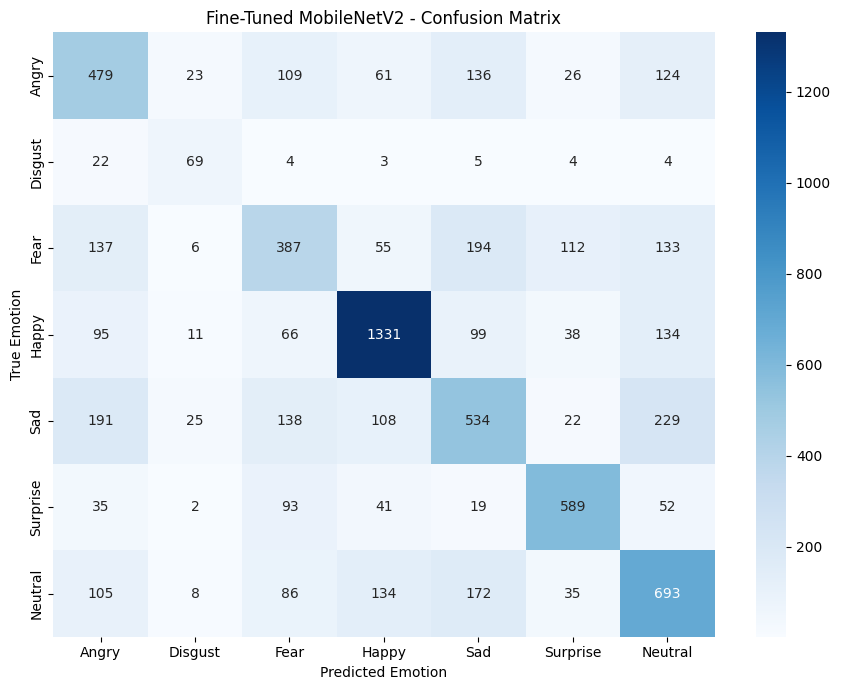

In [47]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

mobilenet_ft_cm = confusion_matrix(y_test, mobilenet_ft_preds)

plt.figure(figsize=(9, 7))
sns.heatmap(
    mobilenet_ft_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Fine-Tuned MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.show()

Normalized Confusion Matrix
We normalize each row of the confusion matrix so the values represent proportions of the true emotion class. This makes it easier to compare performance across emotion classes with different sample counts.

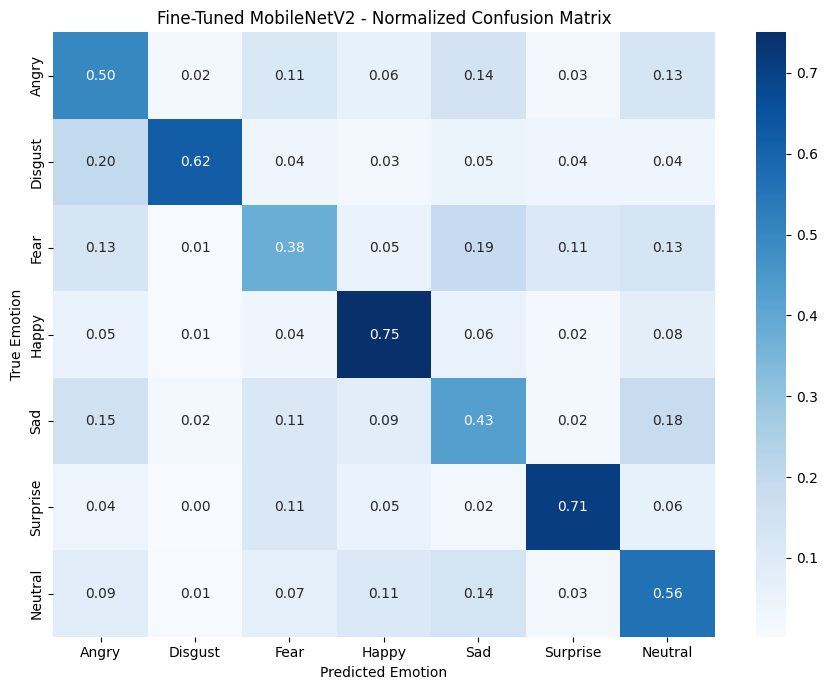

In [48]:
mobilenet_ft_cm_normalized = confusion_matrix(
    y_test,
    mobilenet_ft_preds,
    normalize="true"
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    mobilenet_ft_cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Fine-Tuned MobileNetV2 - Normalized Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.show()

We identify test images where the model’s predicted emotion differs from the true label. Displaying a sample of these images helps us visually inspect the fine-tuned model’s classification errors.

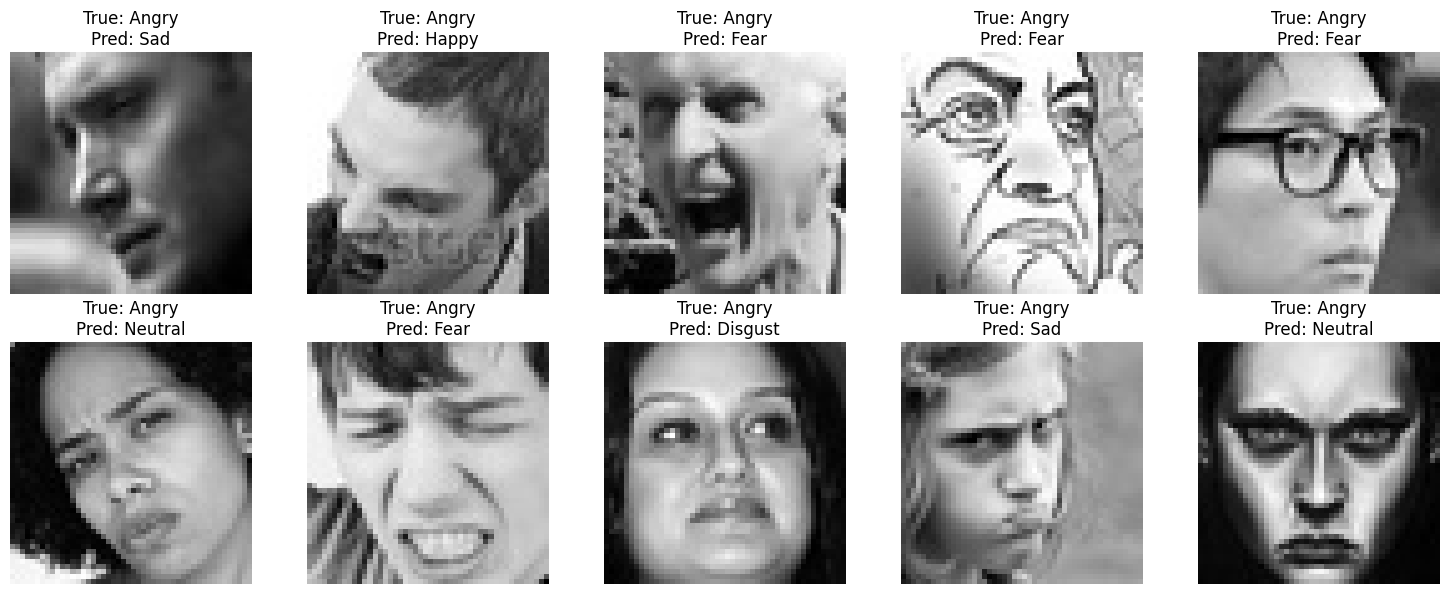

Total misclassified images: 3096


In [49]:
import numpy as np
import matplotlib.pyplot as plt

# Find test images where the prediction is incorrect
mobilenet_ft_misclassified = np.where(
    mobilenet_ft_preds != y_test
)[0]

# Display up to 10 misclassified images
num_images = min(10, len(mobilenet_ft_misclassified))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i in range(num_images):
    idx = mobilenet_ft_misclassified[i]

    # Display the original 48x48 grayscale image
    axes[i].imshow(X_test[idx].squeeze(), cmap="gray")
    axes[i].set_title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[mobilenet_ft_preds[idx]]}"
    )
    axes[i].axis("off")

for i in range(num_images, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

print("Total misclassified images:", len(mobilenet_ft_misclassified))

Save Evaluation Metrics
We save the fine-tuned MobileNetV2’s evaluation metrics and classification report as a JSON file. This allows us to compare its performance with the Custom CNN and other models later.

In [50]:
import os
import json
from sklearn.metrics import classification_report

os.makedirs(results_dir, exist_ok=True)

mobilenet_ft_results = {
    "model": "MobileNetV2 Fine-Tuning",
    "test_samples": int(len(y_test)),
    "misclassified_samples": int(len(mobilenet_ft_misclassified)),
    "accuracy": float(mobilenet_ft_accuracy),
    "macro_precision": float(mobilenet_ft_precision),
    "macro_recall": float(mobilenet_ft_recall),
    "macro_f1": float(mobilenet_ft_f1),
    "classification_report": classification_report(
        y_test,
        mobilenet_ft_preds,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
}

with open(
    os.path.join(results_dir, "mobilenetv2_finetuned_metrics.json"),
    "w"
) as f:
    json.dump(mobilenet_ft_results, f, indent=4)

print("Saved fine-tuned MobileNetV2 metrics.")

Saved fine-tuned MobileNetV2 metrics.


We save the raw and normalized confusion matrices as PNG files in the evaluation results folder for documentation and comparison with the other models.

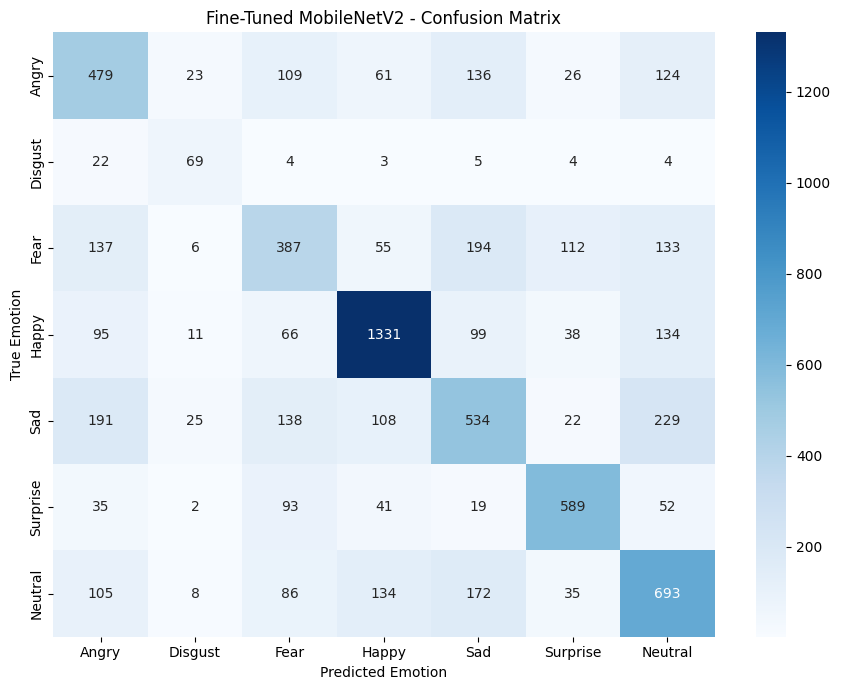

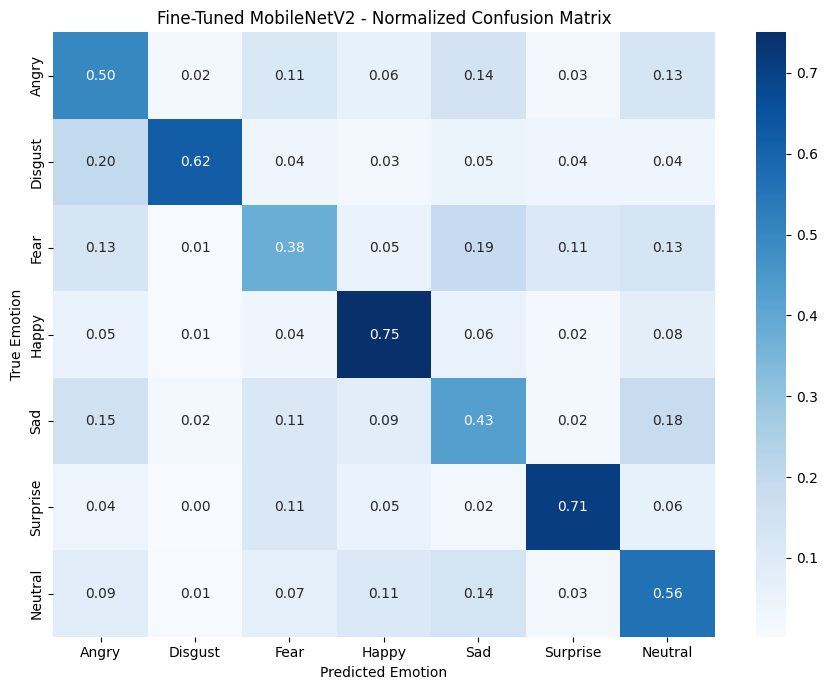

Fine-tuned MobileNetV2 confusion matrix plots saved.


In [51]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

os.makedirs(results_dir, exist_ok=True)

# Save raw confusion matrix
plt.figure(figsize=(9, 7))
sns.heatmap(
    mobilenet_ft_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Fine-Tuned MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.savefig(
    os.path.join(results_dir, "mobilenetv2_finetuned_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Save normalized confusion matrix
plt.figure(figsize=(9, 7))
sns.heatmap(
    mobilenet_ft_cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Fine-Tuned MobileNetV2 - Normalized Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.savefig(
    os.path.join(
        results_dir,
        "mobilenetv2_finetuned_normalized_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Fine-tuned MobileNetV2 confusion matrix plots saved.")

We visualize a sample of test images that the fine-tuned MobileNetV2 model classified incorrectly. Each image is labeled with its true emotion, predicted emotion, and prediction confidence. This helps us inspect common classification errors.

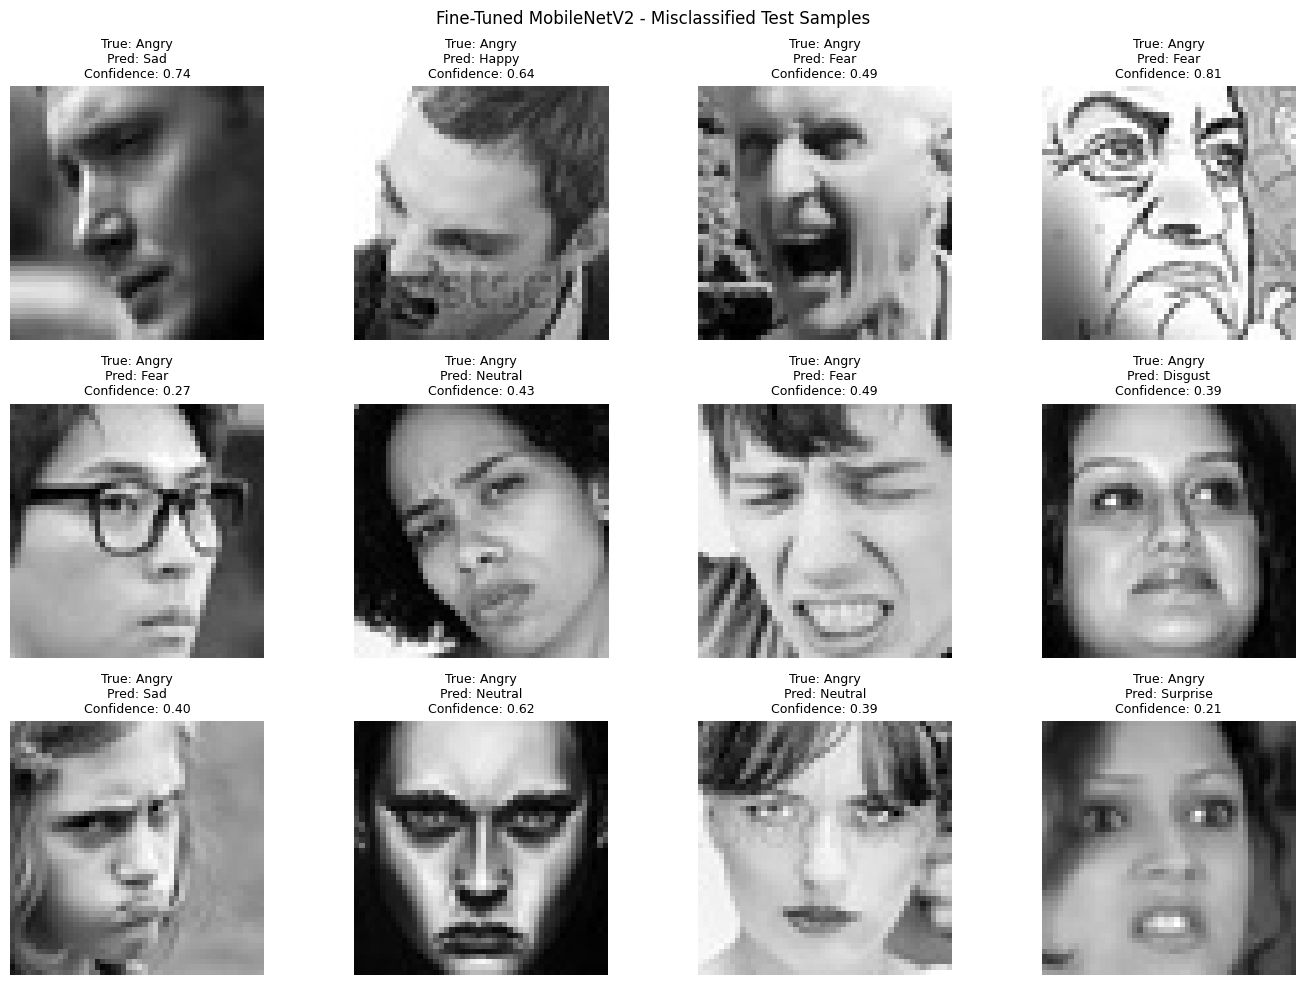

Misclassified sample grid saved.


In [52]:
import os
import matplotlib.pyplot as plt
import numpy as np

num_samples = min(12, len(mobilenet_ft_misclassified))
sample_indices = mobilenet_ft_misclassified[:num_samples]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for ax, idx in zip(axes, sample_indices):
    image = X_test[idx].squeeze()
    true_label = class_names[y_test[idx]]
    predicted_label = class_names[mobilenet_ft_preds[idx]]
    confidence = mobilenet_ft_probs[idx][mobilenet_ft_preds[idx]]

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"True: {true_label}\nPred: {predicted_label}\nConfidence: {confidence:.2f}",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[num_samples:]:
    ax.axis("off")

fig.suptitle("Fine-Tuned MobileNetV2 - Misclassified Test Samples")
fig.tight_layout()

fig.savefig(
    os.path.join(results_dir, "mobilenetv2_finetuned_misclassified_samples.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Misclassified sample grid saved.")

Grad-CAM highlights image regions that contribute to a model’s prediction. We first identify the last convolutional layer of the fine-tuned MobileNetV2, whose feature maps will be used to create the heatmap.

In [53]:
import tensorflow as tf

conv_layers = [
    layer for layer in mobilenet_ft.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
]

for layer in conv_layers[-5:]:
    print(layer.name, layer.output.shape)

last_conv_layer_name = conv_layers[-1].name
print("Last convolutional layer:", last_conv_layer_name)

block_15_expand (None, 3, 3, 960)
block_15_project (None, 3, 3, 160)
block_16_expand (None, 3, 3, 960)
block_16_project (None, 3, 3, 320)
Conv_1 (None, 3, 3, 1280)
Last convolutional layer: Conv_1


We create a model that returns both the last convolutional layer’s feature maps and the final emotion predictions. These outputs are used to calculate which image regions contributed most to the predicted emotion.

In [54]:
last_conv_layer = mobilenet_ft.get_layer("Conv_1")

grad_model = tf.keras.Model(
    inputs=mobilenet_ft.inputs,
    outputs=[last_conv_layer.output, mobilenet_ft.output]
)

print("Grad-CAM model created.")
print("Feature map shape:", grad_model.outputs[0].shape)
print("Prediction shape:", grad_model.outputs[1].shape)

Grad-CAM model created.
Feature map shape: (None, 3, 3, 1280)
Prediction shape: (None, 7)


We generate a Grad-CAM heatmap for a test image. The heatmap highlights regions that contributed most to the model’s predicted emotion; warmer areas indicate stronger influence.

In [55]:
def make_mobilenet_gradcam(image, grad_model):
    image_batch = tf.convert_to_tensor(image[np.newaxis, ...], dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image_batch, training=False)
        predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    gradients = tape.gradient(class_score, conv_outputs)

    # Average gradients across the spatial dimensions
    weights = tf.reduce_mean(gradients, axis=(1, 2))

    # Combine feature maps using the gradient weights
    conv_outputs = conv_outputs[0]
    weights = weights[0]
    heatmap = tf.reduce_sum(conv_outputs * weights, axis=-1)

    # Keep positive contributions and normalize
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), int(predicted_class.numpy())


# Generate Grad-CAM for the first test image
sample_index = 0
sample_image = X_test_mobilenet[sample_index]

heatmap, predicted_class = make_mobilenet_gradcam(
    sample_image,
    grad_model
)

print("Predicted emotion:", class_names[predicted_class])
print("Heatmap shape:", heatmap.shape)

Predicted emotion: Angry
Heatmap shape: (3, 3)


We resize the Grad-CAM heatmap to match the original test image and overlay it on the face. This visualization helps us inspect which regions influenced the fine-tuned MobileNetV2’s prediction.

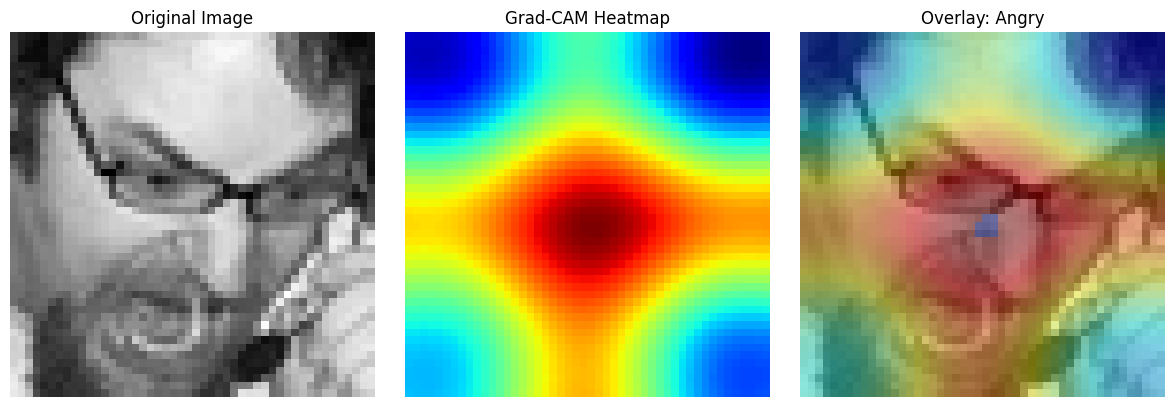

Fine-tuned MobileNetV2 Grad-CAM visualization saved.


In [56]:
import cv2
import matplotlib.pyplot as plt
import os

# Resize the 3x3 heatmap to the original image size
heatmap_resized = cv2.resize(
    heatmap,
    (48, 48),
    interpolation=cv2.INTER_CUBIC
)

# Convert the grayscale image to RGB for the overlay
original_image = X_test[sample_index].squeeze()
original_rgb = cv2.cvtColor(
    (original_image * 255).astype("uint8"),
    cv2.COLOR_GRAY2RGB
)

# Create a colored heatmap
heatmap_uint8 = np.uint8(255 * heatmap_resized)
colored_heatmap = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
colored_heatmap = cv2.cvtColor(colored_heatmap, cv2.COLOR_BGR2RGB)

# Overlay the heatmap on the original image
overlay = cv2.addWeighted(original_rgb, 0.6, colored_heatmap, 0.4, 0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original_image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(heatmap_resized, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title(f"Overlay: {class_names[predicted_class]}")

for ax in axes:
    ax.axis("off")

fig.tight_layout()
fig.savefig(
    os.path.join(results_dir, "mobilenetv2_finetuned_gradcam.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Fine-tuned MobileNetV2 Grad-CAM visualization saved.")

We compare the Custom CNN and fine-tuned MobileNetV2 using the same FER-2013 test set. We report accuracy, macro precision, macro recall, macro F1-score, and test loss to compare their overall performance.

In [64]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def calculate_model_metrics(y_true, y_pred, y_probs):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Test Loss": float(tf.reduce_mean(
            tf.keras.losses.sparse_categorical_crossentropy(
                y_true, y_probs
            )
        ).numpy())
    }

comparison = pd.DataFrame({
    "Custom CNN": calculate_model_metrics(
        y_test, custom_cnn_preds, custom_cnn_probs
    ),
    "MobileNetV2 Fine-Tuning": calculate_model_metrics(
        y_test, mobilenet_ft_preds, mobilenet_ft_probs
    )
}).T

display(comparison.round(4))

comparison.to_csv(
    os.path.join(results_dir, "model_comparison.csv")
)

print("Model comparison saved.")

,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Test Loss
Custom CNN,0.5653,0.5367,0.5575,0.5443,1.1481
MobileNetV2 Fine-Tuning,0.5687,0.5451,0.5641,0.5525,1.1838


Model comparison saved.


The fine-tuned MobileNetV2 achieved slightly higher accuracy (56.87%) and macro F1-score (0.5525) than the Custom CNN (56.53% and 0.5443). It also had higher macro precision and recall, indicating a modest improvement across the seven emotion classes. The Custom CNN had a slightly lower test loss (1.1481 compared with 1.1838), so the fine-tuned model’s advantage is not reflected in every metric. Overall, both models performed similarly, with fine-tuned MobileNetV2 showing a small advantage in classification metrics.

Confusion-Matrix Analysis:

Both models classify Happy and Surprise relatively well, while Fear is the most difficult emotion to recognize. The Custom CNN correctly classifies 34% of Fear images, and fine-tuned MobileNetV2 correctly classifies 38%. Fear is often predicted as Sad (18–19%) or Angry (13–15%).

Both models also confuse Sad and Neutral. The Custom CNN predicts 25% of Sad images as Neutral, while fine-tuned MobileNetV2 predicts 18% as Neutral. Fine-tuned MobileNetV2 improves the correct classification rate for Sad from 37% to 43%, and for Disgust from 59% to 62%. However, its Happy and Surprise recall are slightly lower than the Custom CNN.

These errors may occur because some facial expressions share visual features, and facial images can vary in pose, lighting, intensity, and individual appearance. Overall, fine-tuned MobileNetV2 improves recognition for some classes, but both models still struggle to distinguish visually similar emotions.

Grad-CAM Interpretation
visualizations:

The Grad-CAM heatmaps highlight image regions that contributed to the models’ predictions. In the shown fine-tuned MobileNetV2 example, stronger activation appears around the central face, including the nose and nearby facial area. This suggests that these regions influenced the prediction for this image. However, Grad-CAM highlights model-relevant regions and does not prove that the model understands emotion or relies on the same facial cues a human would.

In [67]:
import os

for filename in sorted(os.listdir(results_dir)):
    print(filename)

custom_cnn_classification_report.txt
custom_cnn_confusion_matrix.png
custom_cnn_gradcam.png
custom_cnn_metrics.json
custom_cnn_misclassified_samples.png
custom_cnn_normalized_confusion_matrix.png
mobilenetv2_finetuned_classification_report.txt
mobilenetv2_finetuned_confusion_matrix.png
mobilenetv2_finetuned_feature_maps.png
mobilenetv2_finetuned_first_conv_filters.png
mobilenetv2_finetuned_gradcam.png
mobilenetv2_finetuned_metrics.json
mobilenetv2_finetuned_misclassified_samples.png
mobilenetv2_finetuned_normalized_confusion_matrix.png
model_comparison.csv


In [66]:
from sklearn.metrics import classification_report
import os

custom_report = classification_report(
    y_test,
    custom_cnn_preds,
    target_names=class_names,
    digits=4
)

mobilenet_report = classification_report(
    y_test,
    mobilenet_ft_preds,
    target_names=class_names,
    digits=4
)

with open(os.path.join(results_dir, "custom_cnn_classification_report.txt"), "w") as f:
    f.write(custom_report)

with open(os.path.join(results_dir, "mobilenetv2_finetuned_classification_report.txt"), "w") as f:
    f.write(mobilenet_report)

print("Classification reports saved.")

Classification reports saved.


In [68]:
!git status

On branch exp/evaluation-explainability
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	results/

nothing added to commit but untracked files present (use "git add" to track)


In [71]:
import os

repo_path = "/content/Facial-Expression-Recognition-CNN"

for root, dirs, files in os.walk(repo_path):
    for file in files:
        if file == "05_evaluation_explainability.ipynb":
            print(os.path.join(root, file))

In [73]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file == "05_evaluation_explainability.ipynb":
            print(os.path.join(root, file))

In [74]:
%cd /content/Facial-Expression-Recognition-CNN

/content/Facial-Expression-Recognition-CNN


In [75]:
!git status

On branch exp/evaluation-explainability
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	results/

nothing added to commit but untracked files present (use "git add" to track)


In [77]:
!git add notebooks/05_evaluation_explainability.ipynb results/evaluation_explainability/


fatal: pathspec 'notebooks/05_evaluation_explainability.ipynb' did not match any files


In [78]:
%cd /content/Facial-Expression-Recognition-CNN
!find /content -name "05_evaluation_explainability.ipynb"
!git status --short

/content/Facial-Expression-Recognition-CNN
?? results/


In [79]:
!git add notebooks/05_evaluation_explainability.ipynb results/

fatal: pathspec 'notebooks/05_evaluation_explainability.ipynb' did not match any files


In [80]:
%cd /content/Facial-Expression-Recognition-CNN
!ls notebooks
!git status --short


/content/Facial-Expression-Recognition-CNN
01_eda.ipynb	       03_ablation_experiments.ipynb
02_baseline_cnn.ipynb  04_transfer_learning.ipynb
?? results/


In [81]:
%cd /content/Facial-Expression-Recognition-CNN
!cp /content/5_evaluation_explainability.ipynb notebooks/
!git add notebooks/5_evaluation_explainability.ipynb results/
!git status --short

/content/Facial-Expression-Recognition-CNN
cp: cannot stat '/content/5_evaluation_explainability.ipynb': No such file or directory
fatal: pathspec 'notebooks/5_evaluation_explainability.ipynb' did not match any files
?? results/
